Modifying KPi-ratio
-------------------

In [1]:
#basic imports and jupyter setup
#import primary model choices
import crflux.models as pm
import matplotlib.pyplot as plt
import numpy as np

#import solver related modules
from MCEq.core import MCEqRun

In [2]:
mceq = MCEqRun(
#provide the string of the interaction model
interaction_model='SIBYLL23E',
#primary cosmic ray flux model
primary_model=(pm.HillasGaisser2012, "H3a"),
# Zenith angle in degrees. 0=vertical, 90=horizontal
theta_deg=0.0,
)

MCEqRun::set_interaction_model(): SIBYLL23E
ParticleManager::_init_default_tracking(): Initializing default tracking categories (pi, K, mu)
MatrixBuilder::_fill_matrices(): No interactions by D_s- ((-431, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s+ ((431, 0)).
MCEqRun::set_density_model(): Setting density profile to CORSIKA ('BK_USStd', None)
MCEqRun::set_primary_model(): Primary model set to Hillas-Gaisser (H3a)


In [3]:
#Power of energy to scale the flux
mag = 3

#obtain energy grid (fixed) of the solution for the x-axis of the plots
e_grid = mceq.e_grid

#Dictionary for results
flux = {}

cos_theta = np.array([1., 0.5, 0.])
angles = np.rad2deg(np.arccos(cos_theta))
# Weight function for modification of pion and kaon distributions
def weight_fun(xmat, egrid, pname, value):
    return (1 + value)*np.ones_like(xmat)


In [4]:
# Set location to IceCube
mceq.set_density_model(('MSIS00_IC',('SouthPole','January')))

MCEqRun::set_density_model(): Setting density profile to MSIS00_IC ('SouthPole', 'January')
MSIS00IceCubeCentered::set_theta(): latitude = -90.00 for zenith angle =  0.00


In [5]:
def compute_fluxes():

    from collections import defaultdict
    flux = defaultdict(list)

    #Sum fluxes, calculated for different angles
    for theta in angles:
        mceq.set_theta_deg(theta)
        mceq.solve()
        #_conv means conventional (mostly pions and kaons)
        flux['numu_pi'].append(mceq.get_solution('pi_numu', mag)
                              + mceq.get_solution('pi_antinumu', mag))
        flux['numu_k'].append(mceq.get_solution('k_numu', mag)
                              + mceq.get_solution('k_numu', mag)
                              + mceq.get_solution('K0_numu', mag)
                              + mceq.get_solution('K0_antinumu', mag))
        flux['numu_pr'].append(mceq.get_solution('pr_numu', mag)
                               + mceq.get_solution('pr_antinumu', mag))
        flux['numu_mu'].append(mceq.get_solution('mu_numu', mag)
                               + mceq.get_solution('mu_antinumu', mag))

        flux['nue_pi'].append(mceq.get_solution('pi_nue', mag)
                              + mceq.get_solution('pi_antinue', mag))
        flux['nue_k'].append(mceq.get_solution('k_nue', mag)
                              + mceq.get_solution('k_nue', mag)
                              + mceq.get_solution('K0_nue', mag)
                              + mceq.get_solution('K0_antinue', mag))
        flux['nue_pr'].append(mceq.get_solution('pr_nue', mag)
                               + mceq.get_solution('pr_antinue', mag))
        flux['nue_total'].append(mceq.get_solution('total_nue', mag)
                             + mceq.get_solution('total_antinue', mag))
        flux['nue_mu'].append(mceq.get_solution('mu_nue', mag)
                               + mceq.get_solution('mu_antinue', mag))
        flux['numu_total'].append(mceq.get_solution('total_numu', mag)
                              + mceq.get_solution('total_antinumu', mag))

        flux['mu_pi'].append(mceq.get_solution('pi_mu+', mag)
                             + mceq.get_solution('pi_mu-', mag))
        flux['mu_k'].append(mceq.get_solution('k_mu+', mag)
                            + mceq.get_solution('k_mu-', mag))
        flux['mu_pr'].append(mceq.get_solution('pr_mu+', mag)
                             + mceq.get_solution('pr_mu-', mag))
        flux['mu_total'].append(mceq.get_solution('total_mu+', mag)
                                + mceq.get_solution('total_mu-', mag))
    return dict(flux)


In [6]:
mceq.unset_mod_pprod()
mceq.matrix_builder.construct_matrices(skip_decay_matrix=True)
nominal = compute_fluxes()

mceq.set_mod_pprod(2212,211,weight_fun, ('a', 0.15))
mceq.set_mod_pprod(2212,-211,weight_fun, ('a', 0.12))
mceq.regenerate_matrices(skip_decay_matrix=True)
piup = compute_fluxes()
mceq.unset_mod_pprod()

mceq.set_mod_pprod(2212,321,weight_fun, ('a', 0.45))
mceq.set_mod_pprod(2212,-321,weight_fun, ('a', 0.55))
mceq.regenerate_matrices(skip_decay_matrix=True)
kdown = compute_fluxes()
mceq.unset_mod_pprod()

MCEqRun::unset_mod_pprod(): Particle production modifications reset to defaults.
MCEqRun::set_primary_model(): Primary model set to Hillas-Gaisser (H3a)
MatrixBuilder::_fill_matrices(): No interactions by D_s- ((-431, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s+ ((431, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s- ((-431, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s+ ((431, 0)).
MSIS00IceCubeCentered::set_theta(): latitude = -89.97 for zenith angle = 60.00
MSIS00IceCubeCentered::set_theta(): latitude = -88.59 for zenith angle = 90.00
MCEqRun::set_mod_pprod(): 2212/211, 211, weight_fun, ('a', 0.15)
MCEqRun::set_mod_pprod(): 2212/-211, -211, weight_fun, ('a', 0.12)
MCEqRun::set_primary_model(): Primary model set to Hillas-Gaisser (H3a)
MatrixBuilder::_fill_matrices(): No interactions by D_s- ((-431, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s+ ((431, 0)).
MSIS00IceCubeCentered::set_theta(): latitude = -90.00 for zenith ang

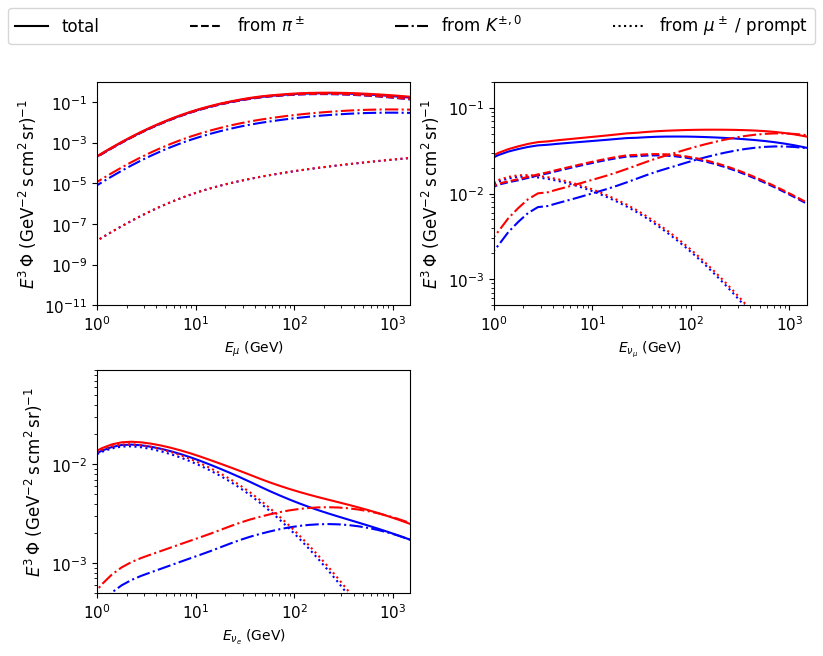

In [7]:
fig = plt.figure(figsize=(8.2,6.6))
gs = fig.add_gridspec(2, 2)

ax_mu = fig.add_subplot(gs[0, 0])
ax_numu = fig.add_subplot(gs[0, 1], sharex=ax_mu)
ax_nue = fig.add_subplot(gs[1, 0], sharex=ax_numu)
ax_empty = fig.add_subplot(gs[1, 1])
ax_empty.axis('off')

# Display the adjusted flux
show_correction = True

# Muon neutrino panel
c = ax_numu.loglog(e_grid, nominal['numu_total'][1],c='b')[0].get_color()
ax_numu.loglog(e_grid, nominal['numu_pi'][1],c=c,ls='--')
ax_numu.loglog(e_grid, nominal['numu_k'][1],c=c,ls='-.')
ax_numu.loglog(e_grid, nominal['numu_mu'][1],c=c,ls=':')
if show_correction:
    c = ax_numu.loglog(e_grid, kdown['numu_total'][1],c='r')[0].get_color()
    ax_numu.loglog(e_grid, kdown['numu_pi'][1],c=c,ls='--')
    ax_numu.loglog(e_grid, kdown['numu_k'][1],c=c,ls='-.')
    ax_numu.loglog(e_grid, kdown['numu_mu'][1],c=c,ls=':')
ax_numu.set_xlim(1.,1500)
ax_numu.set_ylim(5e-4,2e-1)

# Muon panel
c = ax_mu.loglog(e_grid, nominal['mu_total'][1],c='b')[0].get_color()
ax_mu.loglog(e_grid, nominal['mu_pi'][1],c=c,ls='--')
ax_mu.loglog(e_grid, nominal['mu_k'][1],c=c,ls='-.')
ax_mu.loglog(e_grid, nominal['mu_pr'][1],c=c,ls=':')
ax_mu.set_ylabel(r"$E^3\,\Phi$ (GeV$^{-2}\,$s$\,$cm$^{2}\,$sr$)^{-1}$",
                 fontsize='large')
if show_correction:
    c = ax_mu.loglog(e_grid, kdown['mu_total'][1],c='r')[0].get_color()
    ax_mu.loglog(e_grid, kdown['mu_pi'][1],c=c,ls='--')
    ax_mu.loglog(e_grid, kdown['mu_k'][1],c=c,ls='-.')
    ax_mu.loglog(e_grid, kdown['mu_pr'][1],c=c,ls=':')
ax_mu.set_xlim(1.,1500)
ax_mu.set_ylim(10e-12, 10e-1)

# Electron neutrino panel (bottom-left)
c = ax_nue.loglog(e_grid, nominal['nue_total'][1],c='b')[0].get_color()
ax_nue.loglog(e_grid, nominal['nue_pi'][1],c=c,ls='--')
ax_nue.loglog(e_grid, nominal['nue_k'][1],c=c,ls='-.')
ax_nue.loglog(e_grid, nominal['nue_mu'][1],c=c,ls=':')
if show_correction:
    c = ax_nue.loglog(e_grid, kdown['nue_total'][1],c='r')[0].get_color()
    ax_nue.loglog(e_grid, kdown['nue_pi'][1],c=c,ls='--')
    ax_nue.loglog(e_grid, kdown['nue_k'][1],c=c,ls='-.')
    ax_nue.loglog(e_grid, kdown['nue_mu'][1],c=c,ls=':')
ax_nue.set_xlim(1.,1500)
ax_nue.set_ylim(5e-4,9e-2)

ax_numu.set_xlabel(r'$E_{\nu_\mu}$ (GeV)')
ax_mu.set_xlabel(r'$E_{\mu}$ (GeV)')
ax_nue.set_xlabel(r'$E_{\nu_e}$ (GeV)')

ax_numu.set_ylabel(r"$E^3\,\Phi$ (GeV$^{-2}\,$s$\,$cm$^{2}\,$sr$)^{-1}$",
                   fontsize='large')
ax_nue.set_ylabel(r"$E^3\,\Phi$ (GeV$^{-2}\,$s$\,$cm$^{2}\,$sr$)^{-1}$",
                  fontsize='large')

for ax in [ax_numu, ax_mu, ax_nue]:
    [tick.label1.set_fontsize(11) for tick in ax.xaxis.get_major_ticks()]
    [tick.label1.set_fontsize(11) for tick in ax.yaxis.get_major_ticks()]

for ax in [ax_numu, ax_mu, ax_nue]:
    ax.grid(False)
# Make legend for components
figleg_lines,figleg_labels = [], []
for m, ls in zip(['total', r'from $\pi^\pm$', r'from $K^{\pm,0}$', r'from $\mu^\pm$ / prompt'],
                 ['-','--','-.',':']):
    figleg_lines.append(plt.plot([0,0],[0,0],ls=ls,color='k')[0])
    figleg_labels.append(m)
plt.figlegend(figleg_lines,figleg_labels,
              loc='upper center',mode='expand',ncol=4,frameon=True, fontsize='large')
plt.tight_layout(rect=[0.0,0.,1.,.9], w_pad=0.7, h_pad=0.8)
# plt.savefig('flux_components.pdf',dpi=300)

